In [ ]:
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import human_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))

# The number of cores may need modifying depending on your current machine.
n_procs = 10

In [2]:
from urllib.request import urlretrieve

data_url = ('https://raw.githubusercontent.com/jonescompneurolab/hnn/master/data/MEG_detection_data/yes_trial_S1_ERP_all_avg.txt')
urlretrieve(data_url, 'yes_trial_S1_ERP_all_avg.txt')
exp_dpl = read_dipole('yes_trial_S1_ERP_all_avg.txt')

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:82: UserWarning: No external drives or biases loaded
  warnings.warn('No external drives or biases loaded', UserWarning)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

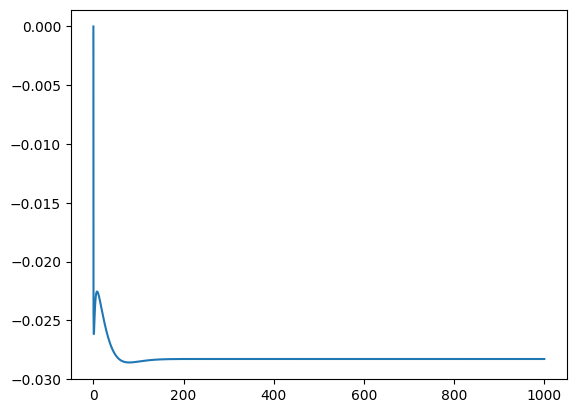

In [ ]:
tstop = 1000


net_no_drives = human_ET_model()
net_no_drives.set_cell_positions(inplane_distance=30.)

# depths = list(range(-325, 2150, 100))
# electrode_pos = [(135, 135, dep) for dep in depths]
# net_no_drives.add_electrode_array('shank1', electrode_pos)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_net_no_drives = simulate_dipole(net_no_drives, tstop=tstop, n_trials=1, bsl_cor='none')[0]
# dpl_net_no_drives.scale(scale_factor)
# dpl_net_no_drives.smooth(smooth_window_len)

# plt.plot(exp_dpl.times,exp_dpl.data['agg'])
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['agg'])

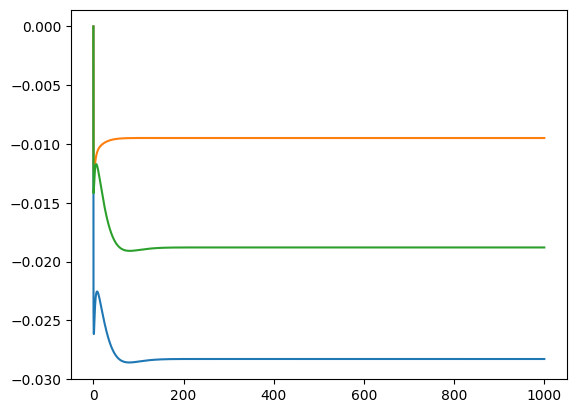

In [4]:
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['agg'])
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['L2'])
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['L5'])

In [5]:
bsl_dipole_ca = {'times': dpl_net_no_drives.times.tolist(),
                 'L2': dpl_net_no_drives.data['L2'].tolist(),
                 'L5': dpl_net_no_drives.data['L5'].tolist()}

import json
with open('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/param/bsl_dipole_ca.json', 'w') as f:
    json.dump(bsl_dipole_ca, f, indent=4, ensure_ascii=False)


In [ ]:
net_no_drives = human_ET_model()
net_no_drives.set_cell_positions(inplane_distance=30.)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_net_no_drives = simulate_dipole(net_no_drives, tstop=tstop, n_trials=1, bsl_cor='calcium')[0]

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:82: UserWarning: No external drives or biases loaded
  warnings.warn('No external drives or biases loaded', UserWarning)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

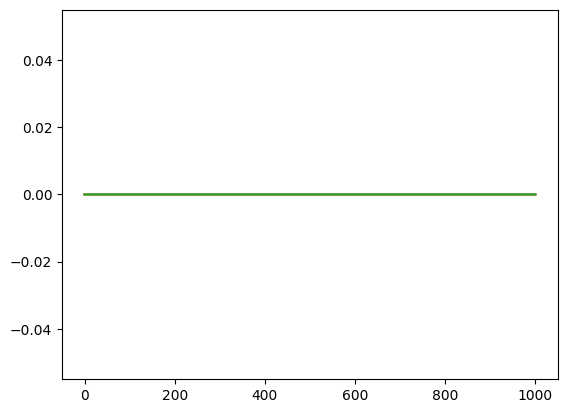

In [8]:
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['agg'])
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['L2'])
plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['L5'])